## Cell 1 — Project title


# Loan Amount Prediction Using Machine Learning

**Project Type:** Supervised Machine Learning - Regression

**Objective:** Predict loan amounts using applicant financial information, credit score, and asset values.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Joblib, and Streamlit.

**Workflow:** Data Collection → Data Cleaning → EDA → Feature Engineering → Model Training → Model Evaluation → Model Saving → Web Application.


## Cell 2 — Import library

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Cell 3 — Load the dataset

In [46]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

Training dataset shape: (32000, 13)
Testing dataset shape: (8000, 12)


In [47]:
train_df.head()

,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,0.0,Graduate,No,NaN,7271300.0,5.0,622.0,6572296.0,12264202.0,NaN,4471627.0,0
1,2,2.0,Not Graduate,Yes,2832292.0,NaN,9.0,482.0,3274507.0,16079677.0,2643225.0,3021958.0,1
2,3,2.0,Graduate,No,2594879.0,8265934.0,16.0,786.0,179550.0,1361037.0,9057816.0,NaN,0
3,4,4.0,Graduate,No,2497120.0,26116812.0,16.0,352.0,16697499.0,NaN,0.0,983214.0,0
4,5,5.0,Not Graduate,Yes,NaN,4071241.0,19.0,381.0,NaN,2788429.0,7977004.0,11154770.0,1


In [48]:
test_df.tail()

,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
7995,39996,5.0,Graduate,Yes,623787.0,22615313.0,18.0,NaN,0.0,2798695.0,2476873.0,2496111.0
7996,39997,1.0,Not Graduate,Yes,6691017.0,33155722.0,NaN,549.0,2157214.0,NaN,4569769.0,9638821.0
7997,39998,2.0,Graduate,No,9348087.0,9482575.0,NaN,969.0,0.0,1187990.0,27757308.0,2558806.0
7998,39999,5.0,Not Graduate,Yes,4005367.0,30447507.0,9.0,788.0,4636662.0,9119104.0,29390190.0,8627869.0
7999,40000,2.0,Not Graduate,Yes,3056948.0,39149648.0,13.0,597.0,4912424.0,7608361.0,1264909.0,11595999.0


## Cell 4 — Understand the dataset

In [49]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

print("Number of training rows:", train_df.shape[0])
print("Number of training columns:", train_df.shape[1])

print("Number of testing rows:", test_df.shape[0])
print("Number of testing columns:", test_df.shape[1])

Training Dataset Shape: (32000, 13)
Testing Dataset Shape: (8000, 12)
Number of training rows: 32000
Number of training columns: 13
Number of testing rows: 8000
Number of testing columns: 12


In [50]:
print("Training Dataset Columns:")
print(train_df.columns.tolist())

print("\nTesting Dataset Columns:")
print(test_df.columns.tolist())

Training Dataset Columns:
['id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']

Testing Dataset Columns:
['id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [51]:
print("Training Dataset Information:")
train_df.info()

print("\nTesting Dataset Information:")
test_df.info()

Training Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000 entries, 0 to 31999
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        32000 non-null  int64  
 1   no_of_dependents          30395 non-null  float64
 2   education                 30263 non-null  object 
 3   self_employed             29377 non-null  object 
 4   income_annum              29865 non-null  float64
 5   loan_amount               29082 non-null  float64
 6   loan_term                 30103 non-null  float64
 7   cibil_score               29230 non-null  float64
 8   residential_assets_value  29381 non-null  float64
 9   commercial_assets_value   29903 non-null  float64
 10  luxury_assets_value       30166 non-null  float64
 11  bank_asset_value          30082 non-null  float64
 12  loan_status               32000 non-null  int64  
dtypes: float64(9), int64(2), object

In [52]:
print("Training Dataset Statistical Summary:")
display(train_df.describe(include="all"))

Training Dataset Statistical Summary:


,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
count,32000.000000,30395.000000,30263,29377,2.986500e+04,2.908200e+04,30103.000000,29230.000000,2.938100e+04,2.990300e+04,3.016600e+04,3.008200e+04,32000.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,Not Graduate,Yes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,16081,15939,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,16000.500000,1.951867,NaN,NaN,3.523466e+06,1.285102e+07,12.367206,661.731201,3.956638e+06,6.212830e+06,1.119524e+07,4.702795e+06,0.544687
std,9237.748643,1.631178,NaN,NaN,2.920311e+06,9.177297e+06,5.440251,173.093587,5.339316e+06,5.490717e+06,8.793568e+06,3.770261e+06,0.498007
min,1.000000,0.000000,NaN,NaN,0.000000e+00,0.000000e+00,0.000000,223.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,8000.750000,0.000000,NaN,NaN,8.302840e+05,5.416666e+06,9.000000,529.000000,0.000000e+00,1.880555e+06,4.067125e+06,1.596127e+06,0.000000
50%,16000.500000,2.000000,NaN,NaN,2.961480e+06,1.174617e+07,13.000000,663.500000,1.812942e+06,4.531977e+06,9.802424e+06,3.998888e+06,1.000000
75%,24000.250000,3.000000,NaN,NaN,5.827615e+06,1.870117e+07,17.000000,811.000000,5.528413e+06,9.059980e+06,1.671170e+07,7.027444e+06,1.000000


In [53]:
print("Missing Values in Training Dataset:")
display(train_df.isnull().sum())

print("Missing Values in Testing Dataset:")
display(test_df.isnull().sum())

Missing Values in Training Dataset:


id                             0
no_of_dependents            1605
education                   1737
self_employed               2623
income_annum                2135
loan_amount                 2918
loan_term                   1897
cibil_score                 2770
residential_assets_value    2619
commercial_assets_value     2097
luxury_assets_value         1834
bank_asset_value            1918
loan_status                    0
dtype: int64

Missing Values in Testing Dataset:


id                            0
no_of_dependents            421
education                   455
self_employed               652
income_annum                518
loan_amount                 732
loan_term                   490
cibil_score                 706
residential_assets_value    694
commercial_assets_value     489
luxury_assets_value         487
bank_asset_value            475
dtype: int64

In [54]:
print("Duplicate rows in training dataset:", train_df.duplicated().sum())
print("Duplicate rows in testing dataset:", test_df.duplicated().sum())

Duplicate rows in training dataset: 0
Duplicate rows in testing dataset: 0


## Cell 5 — Validate the target column

In [55]:
# Normalize column-name capitalization for target identification
target_column = "loan_amount"

if target_column in train_df.columns:
    print("Target column found:", target_column)
    print("Target data type:", train_df[target_column].dtype)
    print("Known target values:", train_df[target_column].notna().sum())
    print("Missing target values:", train_df[target_column].isna().sum())
else:
    raise ValueError("The loan_amount column was not found in the training dataset.")


Target column found: loan_amount
Target data type: float64
Known target values: 29082
Missing target values: 2918


In [56]:
train_missing = pd.DataFrame({
    "Missing Values": train_df.isnull().sum(),
    "Missing Percentage": train_df.isnull().mean() * 100
})

test_missing = pd.DataFrame({
    "Missing Values": test_df.isnull().sum(),
    "Missing Percentage": test_df.isnull().mean() * 100
})

print("Training dataset missing values:")
display(train_missing.round(2))

print("Testing dataset missing values:")
display(test_missing.round(2))

Training dataset missing values:


,Missing Values,Missing Percentage
id,0,0.00
no_of_dependents,1605,5.02
education,1737,5.43
self_employed,2623,8.20
income_annum,2135,6.67
loan_amount,2918,9.12
loan_term,1897,5.93
cibil_score,2770,8.66
residential_assets_value,2619,8.18
commercial_assets_value,2097,6.55


Testing dataset missing values:


,Missing Values,Missing Percentage
id,0,0.00
no_of_dependents,421,5.26
education,455,5.69
self_employed,652,8.15
income_annum,518,6.48
loan_amount,732,9.15
loan_term,490,6.12
cibil_score,706,8.82
residential_assets_value,694,8.67
commercial_assets_value,489,6.11


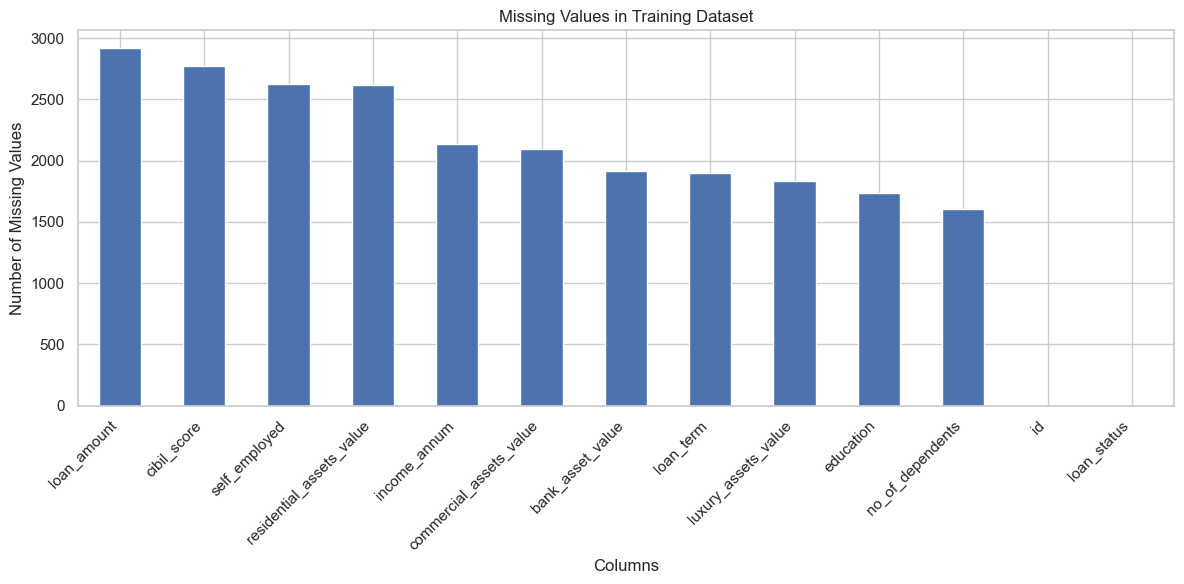

In [57]:
plt.figure(figsize=(12, 6))

train_df.isnull().sum().sort_values(ascending=False).plot(kind="bar")

plt.title("Missing Values in Training Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [58]:
print("Duplicate rows in training dataset:", train_df.duplicated().sum())
print("Duplicate rows in testing dataset:", test_df.duplicated().sum())

Duplicate rows in training dataset: 0
Duplicate rows in testing dataset: 0


## Cell 6 — Data cleaning

In [59]:
# Create copies to preserve the original datasets
train_clean = train_df.copy()
test_clean = test_df.copy()

print("Training dataset copied successfully.")
print("Testing dataset copied successfully.")

Training dataset copied successfully.
Testing dataset copied successfully.


In [60]:
# Check duplicates before cleaning
print("Training duplicates:", train_clean.duplicated().sum())
print("Testing duplicates:", test_clean.duplicated().sum())

# Remove duplicate rows
train_clean = train_clean.drop_duplicates().copy()
test_clean = test_clean.drop_duplicates().copy()

print("\nDuplicates removed.")
print("Training shape:", train_clean.shape)
print("Testing shape:", test_clean.shape)

Training duplicates: 0
Testing duplicates: 0

Duplicates removed.
Training shape: (32000, 13)
Testing shape: (8000, 12)


In [61]:
# Numerical columns
numeric_columns = [
    "no_of_dependents",
    "income_annum",
    "loan_amount",
    "loan_term",
    "cibil_score",
    "residential_assets_value",
    "commercial_assets_value",
    "luxury_assets_value",
    "bank_asset_value"
]

# Convert available numerical columns to numeric format
for df in [train_clean, test_clean]:
    for col in numeric_columns:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

print("Data types corrected.")

display(train_clean.dtypes.to_frame(name="Data Type"))

Data types corrected.


,Data Type
id,int64
no_of_dependents,float64
education,object
self_employed,object
income_annum,float64
loan_amount,float64
loan_term,float64
cibil_score,float64
residential_assets_value,float64
commercial_assets_value,float64


In [62]:
# Remove unnecessary spaces from categorical values
categorical_columns = ["education", "self_employed", "loan_status"]

for df in [train_clean, test_clean]:
    for col in categorical_columns:
        if col in df.columns:
            df[col] = df[col].apply(
                lambda value: value.strip() if isinstance(value, str) else value
            )

print("Categorical values cleaned.")

Categorical values cleaned.


In [63]:
print("Missing values in training dataset:")
display(train_clean.isnull().sum().to_frame(name="Missing Values"))

print("Missing values in testing dataset:")
display(test_clean.isnull().sum().to_frame(name="Missing Values"))

Missing values in training dataset:


,Missing Values
id,0
no_of_dependents,1605
education,1737
self_employed,2623
income_annum,2135
loan_amount,2918
loan_term,1897
cibil_score,2770
residential_assets_value,2619
commercial_assets_value,2097


Missing values in testing dataset:


,Missing Values
id,0
no_of_dependents,421
education,455
self_employed,652
income_annum,518
loan_amount,732
loan_term,490
cibil_score,706
residential_assets_value,694
commercial_assets_value,489


In [64]:
print("DATA CLEANING SUMMARY")
print("---------------------")
print("Training dataset shape:", train_clean.shape)
print("Testing dataset shape:", test_clean.shape)

print("\nTotal missing values in training:", train_clean.isnull().sum().sum())
print("Total missing values in testing:", test_clean.isnull().sum().sum())

print("\nTraining dataset preview:")
display(train_clean.head())

DATA CLEANING SUMMARY
---------------------
Training dataset shape: (32000, 13)
Testing dataset shape: (8000, 12)

Total missing values in training: 24153
Total missing values in testing: 6119

Training dataset preview:


,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,0.0,Graduate,No,NaN,7271300.0,5.0,622.0,6572296.0,12264202.0,NaN,4471627.0,0
1,2,2.0,Not Graduate,Yes,2832292.0,NaN,9.0,482.0,3274507.0,16079677.0,2643225.0,3021958.0,1
2,3,2.0,Graduate,No,2594879.0,8265934.0,16.0,786.0,179550.0,1361037.0,9057816.0,NaN,0
3,4,4.0,Graduate,No,2497120.0,26116812.0,16.0,352.0,16697499.0,NaN,0.0,983214.0,0
4,5,5.0,Not Graduate,Yes,NaN,4071241.0,19.0,381.0,NaN,2788429.0,7977004.0,11154770.0,1


## Cell 7 — Exploratory Data Analysis (EDA)

In [65]:
print("Training Dataset Shape:", train_clean.shape)
print("Testing Dataset Shape:", test_clean.shape)

print("\nStatistical Summary:")
display(train_clean.describe(include="all").T)

Training Dataset Shape: (32000, 13)
Testing Dataset Shape: (8000, 12)

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,32000.0,NaN,NaN,NaN,16000.5,9237.748643,1.0,8000.75,16000.5,24000.25,32000.0
no_of_dependents,30395.0,NaN,NaN,NaN,1.951867,1.631178,0.0,0.0,2.0,3.0,5.0
education,30263,2,Not Graduate,16081,NaN,NaN,NaN,NaN,NaN,NaN,NaN
self_employed,29377,2,Yes,15939,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_annum,29865.0,NaN,NaN,NaN,3523465.886657,2920311.312634,0.0,830284.0,2961480.0,5827615.0,11369423.0
loan_amount,29082.0,NaN,NaN,NaN,12851018.582147,9177296.644811,0.0,5416666.0,11746169.0,18701166.0,46044308.0
loan_term,30103.0,NaN,NaN,NaN,12.367206,5.440251,0.0,9.0,13.0,17.0,22.0
cibil_score,29230.0,NaN,NaN,NaN,661.731201,173.093587,223.0,529.0,663.5,811.0,1011.0
residential_assets_value,29381.0,NaN,NaN,NaN,3956637.734522,5339316.21656,0.0,0.0,1812942.0,5528413.0,34562020.0
commercial_assets_value,29903.0,NaN,NaN,NaN,6212830.127579,5490717.195959,0.0,1880555.0,4531977.0,9059979.5,24041102.0


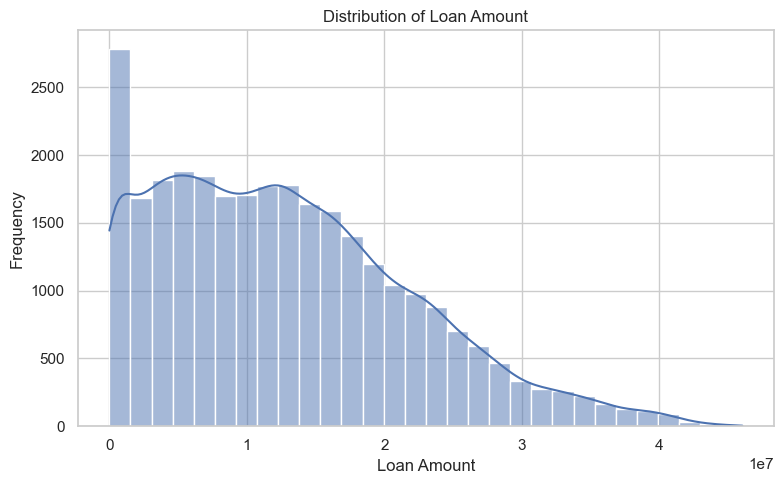

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_clean,
    x="loan_amount",
    bins=30,
    kde=True
)

plt.title("Distribution of Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


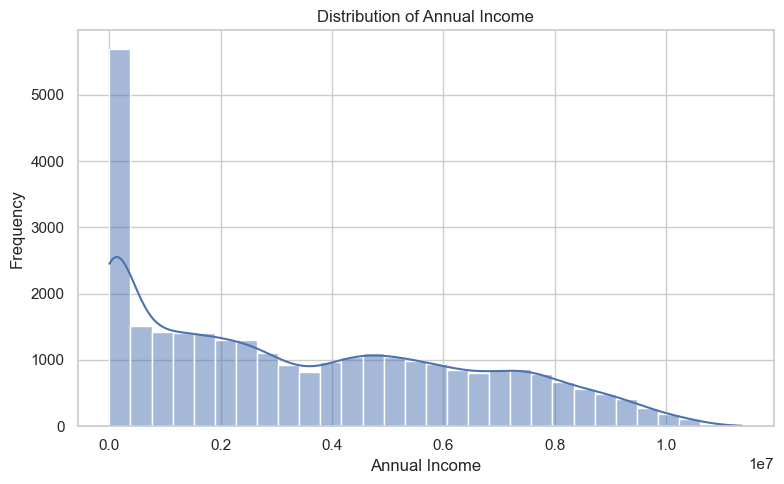

In [67]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_clean,
    x="income_annum",
    bins=30,
    kde=True
)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


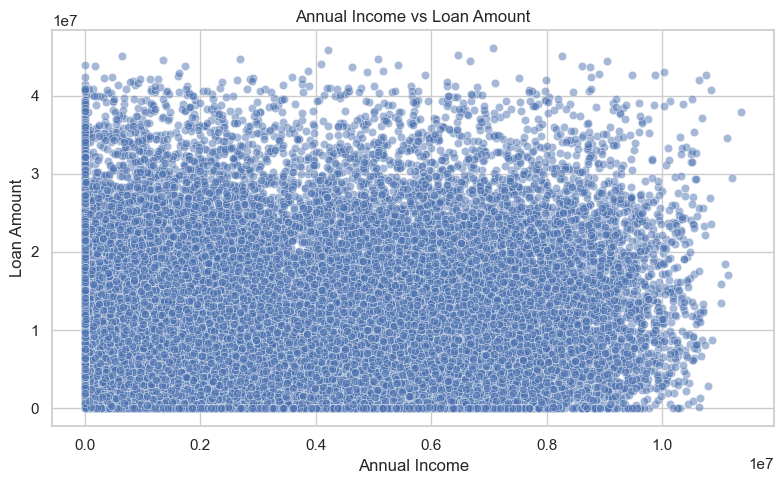

In [68]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=train_clean,
    x="income_annum",
    y="loan_amount",
    alpha=0.5
)

plt.title("Annual Income vs Loan Amount")
plt.xlabel("Annual Income")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

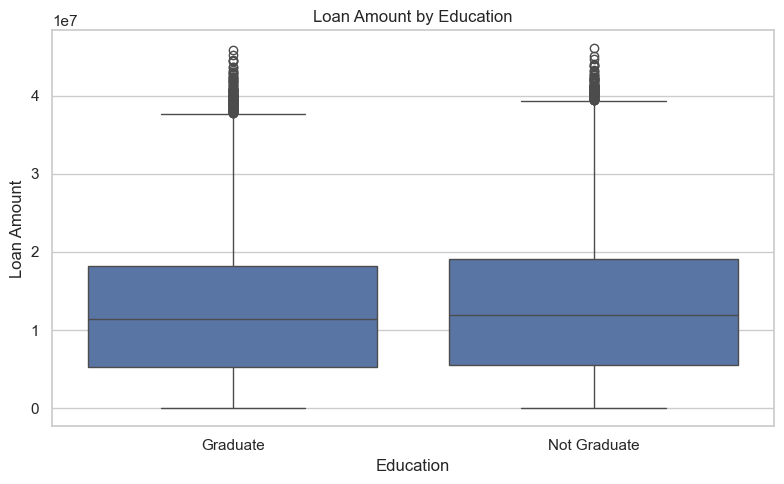

In [69]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_clean,
    x="education",
    y="loan_amount"
)

plt.title("Loan Amount by Education")
plt.xlabel("Education")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

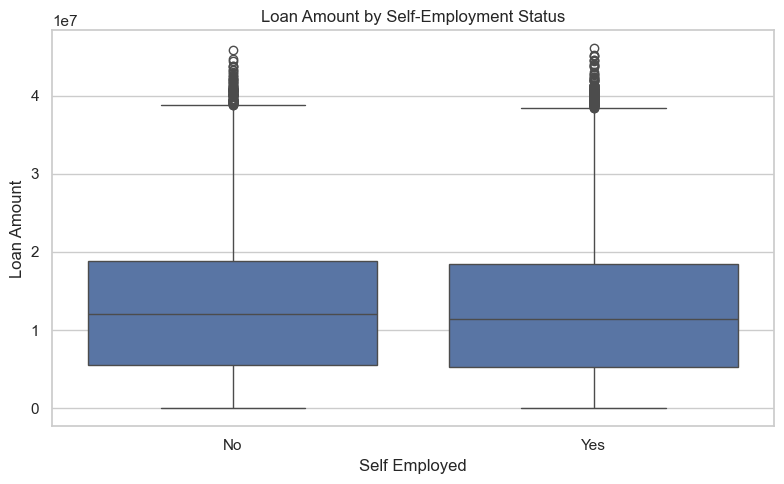

In [70]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_clean,
    x="self_employed",
    y="loan_amount"
)

plt.title("Loan Amount by Self-Employment Status")
plt.xlabel("Self Employed")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

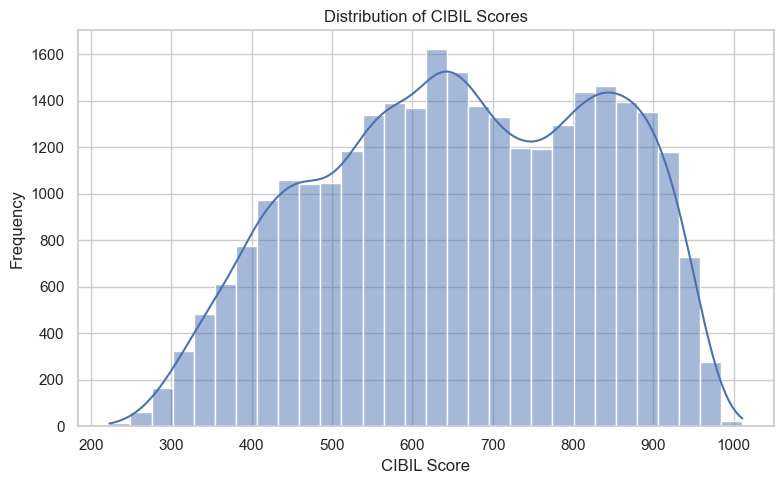

In [71]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_clean,
    x="cibil_score",
    bins=30,
    kde=True
)

plt.title("Distribution of CIBIL Scores")
plt.xlabel("CIBIL Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

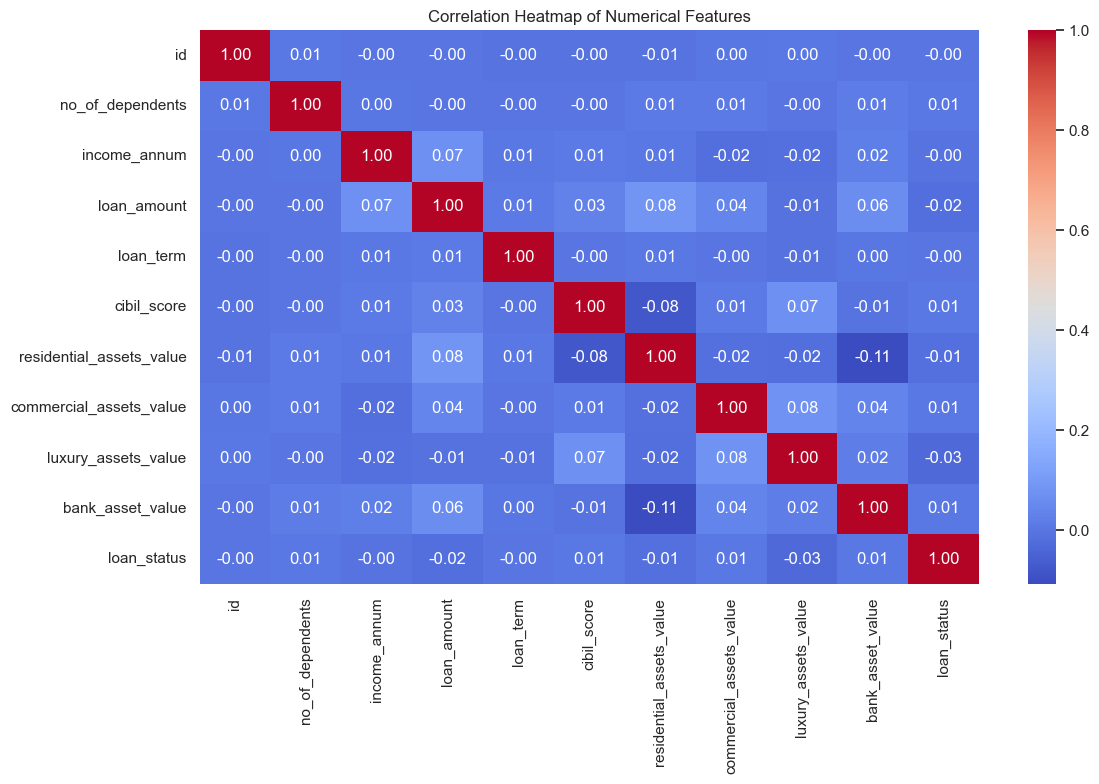

In [72]:
numeric_data = train_clean.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

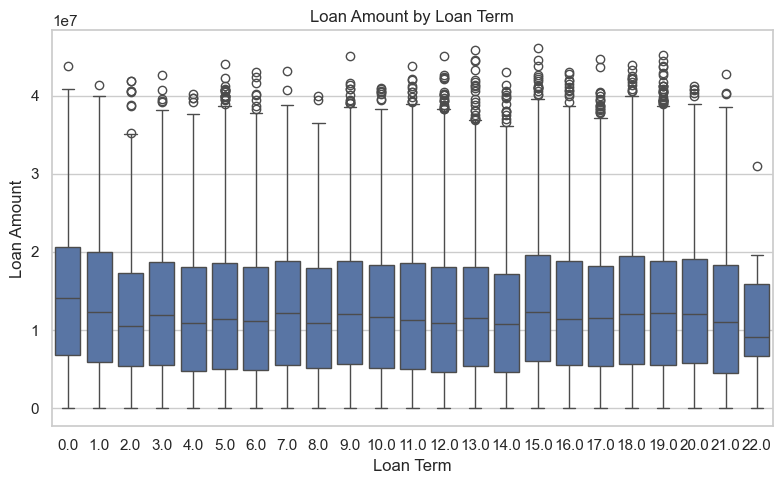

In [73]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_clean,
    x="loan_term",
    y="loan_amount"
)

plt.title("Loan Amount by Loan Term")
plt.xlabel("Loan Term")
plt.ylabel("Loan Amount")
plt.tight_layout()
plt.show()

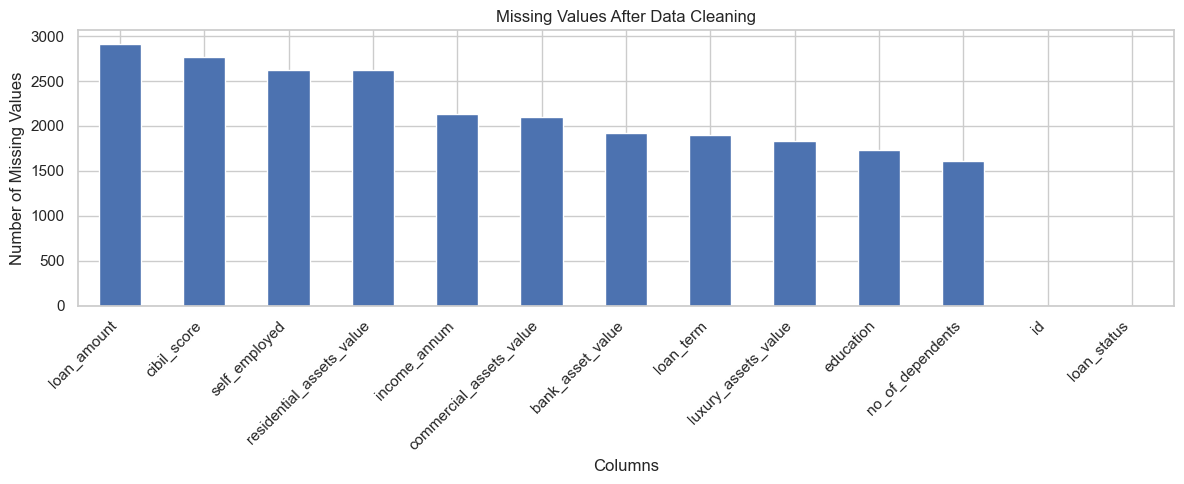

In [74]:
plt.figure(figsize=(12, 5))

train_clean.isnull().sum().sort_values(ascending=False).plot(kind="bar")

plt.title("Missing Values After Data Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Cell 8 — Feature engineering and target selection

In [75]:
# Define target column
target_column = "loan_amount"

# Columns excluded from model inputs
excluded_columns = ["id", "loan_amount", "loan_status"]

# Select features available in both datasets
feature_columns = [
    col for col in train_clean.columns
    if col not in excluded_columns and col in test_clean.columns
]

# Validate target and features
if target_column not in train_clean.columns:
    raise ValueError("Target column 'loan_amount' is missing from the training dataset.")

if not feature_columns:
    raise ValueError("No common input features found between training and testing datasets.")

print("Target column:", target_column)
print("\nSelected input features:")
print(feature_columns)


Target column: loan_amount

Selected input features:
['no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']


In [76]:
# Convert target to numeric
train_clean[target_column] = pd.to_numeric(
    train_clean[target_column], errors="coerce"
)

test_clean[target_column] = pd.to_numeric(
    test_clean[target_column], errors="coerce"
)

# Rows with known target values can be used for supervised learning
labeled_data = train_clean.dropna(subset=[target_column]).copy()

# Rows with missing target values need predictions
missing_target_data = train_clean[
    train_clean[target_column].isna()
].copy()

print("Rows with known loan amounts:", len(labeled_data))
print("Rows with missing loan amounts in training:", len(missing_target_data))
print("Rows with missing loan amounts in testing:",
      test_clean[target_column].isna().sum())

Rows with known loan amounts: 29082
Rows with missing loan amounts in training: 2918
Rows with missing loan amounts in testing: 732


In [77]:
# Input features
X = labeled_data[feature_columns].copy()

# Target variable
y = labeled_data[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

display(X.head())
display(y.head())

Feature matrix shape: (29082, 10)
Target vector shape: (29082,)


,no_of_dependents,education,self_employed,income_annum,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,0.0,Graduate,No,NaN,5.0,622.0,6572296.0,12264202.0,NaN,4471627.0
2,2.0,Graduate,No,2594879.0,16.0,786.0,179550.0,1361037.0,9057816.0,NaN
3,4.0,Graduate,No,2497120.0,16.0,352.0,16697499.0,NaN,0.0,983214.0
4,5.0,Not Graduate,Yes,NaN,19.0,381.0,NaN,2788429.0,7977004.0,11154770.0
5,3.0,Graduate,Yes,0.0,16.0,376.0,4155221.0,12428538.0,15827874.0,1696950.0


0     7271300.0
2     8265934.0
3    26116812.0
4     4071241.0
5    17768160.0
Name: loan_amount, dtype: float64

In [78]:
# Identify feature types
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['no_of_dependents', 'income_annum', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Categorical features:
['education', 'self_employed']


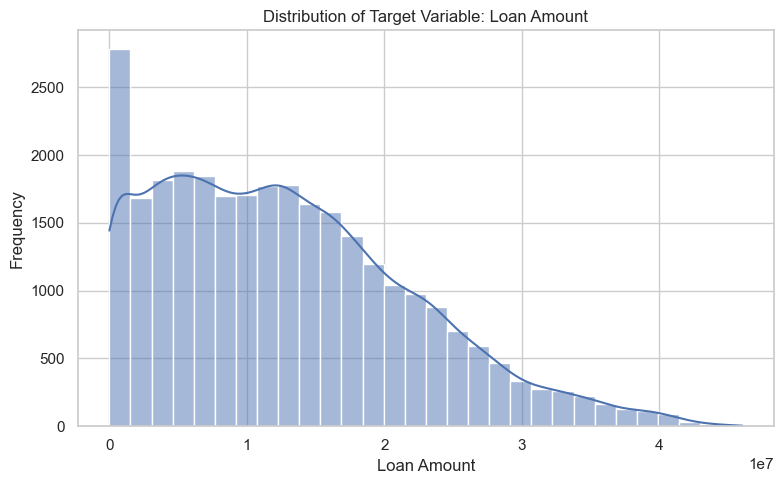

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(y, bins=30, kde=True)

plt.title("Distribution of Target Variable: Loan Amount")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Cell 9 — Data Preprocessing

In [81]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_valid.shape)

Training features: (23265, 10)
Validation features: (5817, 10)
Training target: (23265,)
Validation target: (5817,)


In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [83]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation data using the same fitted preprocessing
X_valid_processed = preprocessor.transform(X_valid)

print("Processed training data shape:", X_train_processed.shape)
print("Processed validation data shape:", X_valid_processed.shape)

Processed training data shape: (23265, 12)
Processed validation data shape: (5817, 12)


In [84]:
import numpy as np

# Convert sparse matrices to arrays only for checking
train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

valid_array = (
    X_valid_processed.toarray()
    if hasattr(X_valid_processed, "toarray")
    else np.asarray(X_valid_processed)
)

print("Missing values in processed training features:",
      np.isnan(train_array).sum())

print("Missing values in processed validation features:",
      np.isnan(valid_array).sum())

Missing values in processed training features: 0
Missing values in processed validation features: 0


## Cell 10 — Model Building and Training

In [86]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using the original training features
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [87]:
# Predict loan amounts for validation records
y_pred = model.predict(X_valid)

print("Actual loan amounts:")
print(y_valid.head(10).to_list())

print("\nPredicted loan amounts:")
print(y_pred[:10])

Actual loan amounts:
[12756510.0, 3507030.0, 8841530.0, 8513038.0, 12970621.0, 10480871.0, 2778381.0, 15071324.0, 9808609.0, 7064378.0]

Predicted loan amounts:
[14425267.055 11543842.8   11147207.99  13759377.07  12577524.955
 13282022.58  10713452.065 14756227.87  11053038.18   7637085.39 ]


In [88]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Actual Loan Amount": y_valid.to_numpy(),
    "Predicted Loan Amount": y_pred
})

comparison_df["Absolute Error"] = abs(
    comparison_df["Actual Loan Amount"] -
    comparison_df["Predicted Loan Amount"]
)

display(comparison_df.head(10))

,Actual Loan Amount,Predicted Loan Amount,Absolute Error
0,12756510.0,1.442527e+07,1668757.055
1,3507030.0,1.154384e+07,8036812.800
2,8841530.0,1.114721e+07,2305677.990
3,8513038.0,1.375938e+07,5246339.070
4,12970621.0,1.257752e+07,393096.045
5,10480871.0,1.328202e+07,2801151.580
6,2778381.0,1.071345e+07,7935071.065
7,15071324.0,1.475623e+07,315096.130
8,9808609.0,1.105304e+07,1244429.180
9,7064378.0,7.637085e+06,572707.390


## Cell 11 — Model Evaluation

In [90]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Generate predictions if not already available
y_pred = model.predict(X_valid)

# Calculate metrics
mae = mean_absolute_error(y_valid, y_pred)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
r2 = r2_score(y_valid, y_pred)

print("Model Evaluation Results")
print("------------------------")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 7571560.39
Root Mean Squared Error (RMSE): 9285451.95
R² Score: 0.0024


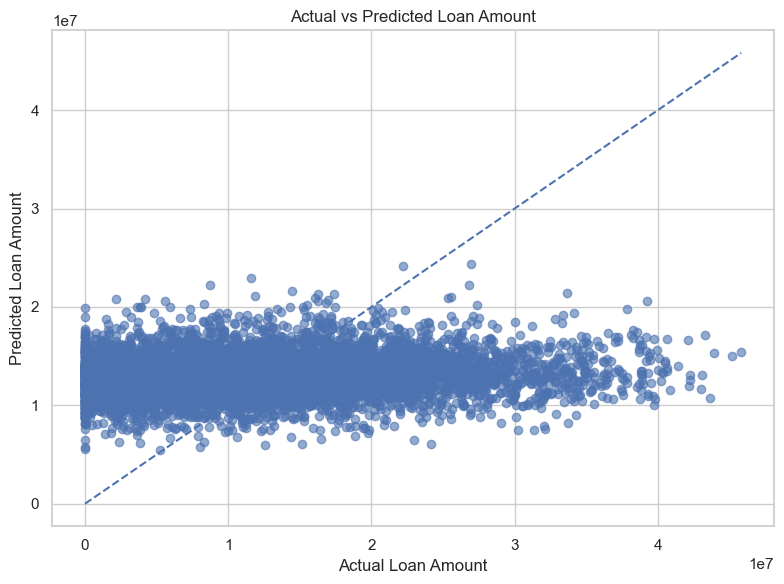

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_valid, y_pred, alpha=0.6)

min_value = min(y_valid.min(), y_pred.min())
max_value = max(y_valid.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Loan Amount")
plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.tight_layout()
plt.show()

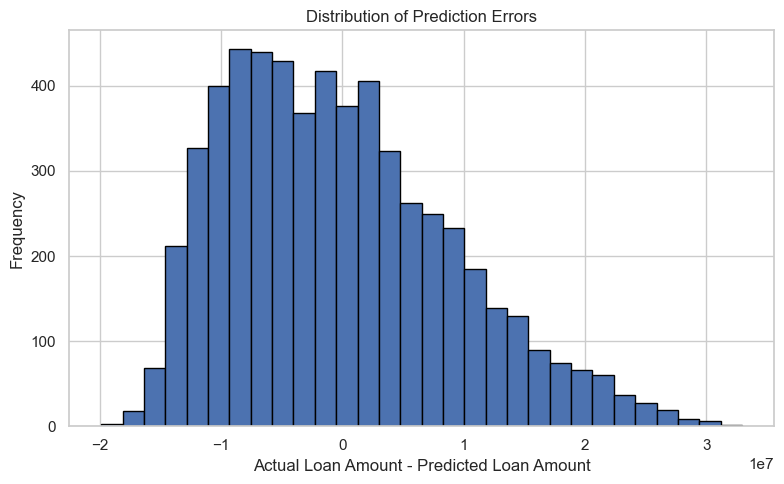

In [92]:
residuals = y_valid.to_numpy() - y_pred

plt.figure(figsize=(8, 5))

plt.hist(residuals, bins=30, edgecolor="black")

plt.title("Distribution of Prediction Errors")
plt.xlabel("Actual Loan Amount - Predicted Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [93]:
evaluation_results = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Value": [mae, rmse, r2]
})

display(evaluation_results)

,Metric,Value
0,MAE,7.571560e+06
1,RMSE,9.285452e+06
2,R² Score,2.362703e-03


## Cell 12 — Predict Missing Loan Amounts

In [95]:
# Create a copy of the cleaned training dataset
train_output = train_clean.copy()

# Identify rows with missing loan amounts
missing_train_mask = train_output["loan_amount"].isna()

print("Missing loan amounts before prediction:",
      missing_train_mask.sum())

# Predict only where loan_amount is missing
if missing_train_mask.any():
    train_output.loc[missing_train_mask, "loan_amount"] = model.predict(
        train_output.loc[missing_train_mask, feature_columns]
    )

print("Missing loan amounts after prediction:",
      train_output["loan_amount"].isna().sum())

display(train_output.head())

Missing loan amounts before prediction: 2918
Missing loan amounts after prediction: 0


,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,0.0,Graduate,No,NaN,7.271300e+06,5.0,622.0,6572296.0,12264202.0,NaN,4471627.0,0
1,2,2.0,Not Graduate,Yes,2832292.0,1.275758e+07,9.0,482.0,3274507.0,16079677.0,2643225.0,3021958.0,1
2,3,2.0,Graduate,No,2594879.0,8.265934e+06,16.0,786.0,179550.0,1361037.0,9057816.0,NaN,0
3,4,4.0,Graduate,No,2497120.0,2.611681e+07,16.0,352.0,16697499.0,NaN,0.0,983214.0,0
4,5,5.0,Not Graduate,Yes,NaN,4.071241e+06,19.0,381.0,NaN,2788429.0,7977004.0,11154770.0,1


In [96]:
# Create a copy of the cleaned testing dataset
test_output = test_clean.copy()

# Identify rows with missing loan amounts
missing_test_mask = test_output["loan_amount"].isna()

print("Missing loan amounts before prediction:",
      missing_test_mask.sum())

# Predict only where loan_amount is missing
if missing_test_mask.any():
    test_output.loc[missing_test_mask, "loan_amount"] = model.predict(
        test_output.loc[missing_test_mask, feature_columns]
    )

print("Missing loan amounts after prediction:",
      test_output["loan_amount"].isna().sum())

display(test_output.head())

Missing loan amounts before prediction: 732
Missing loan amounts after prediction: 0


,id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,32001,1.0,Graduate,Yes,1184682.0,17119708.0,11.0,749.0,0.0,4800216.0,16565306.0,1631095.0
1,32002,0.0,Graduate,No,8920224.0,5040529.0,0.0,989.0,NaN,3590433.0,22490251.0,4153781.0
2,32003,0.0,Not Graduate,Yes,9064660.0,15390179.0,14.0,511.0,1254869.0,6981191.0,12755544.0,1497759.0
3,32004,5.0,Graduate,No,9787483.0,5649434.0,NaN,513.0,1315339.0,421501.0,21345655.0,945687.0
4,32005,1.0,Not Graduate,No,320746.0,2157362.0,13.0,759.0,3273669.0,2587980.0,25049850.0,1374027.0


Submitted By

Name: KUMAR SARANSH Registration Number: RA2411056030052

Project Title: MyAntonomy

Under the Guidance of: Aamir Khan